<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 1: Vector and Matrix Operations for Deep Learning

**Course Outcome**: CO1 – Mathematical Foundations and Optimization  
**Problem Statement**: An e-commerce firm represents customers and products as numeric vectors to power its recommendation engine. Every recommendation is a chain of dot products and matrix multiplications. A small online bookstore has 6 customers and 5 genres. Each customer has a rating vector, and each book has a genre-weight vector. The store wants to score every customer–book pair and find similar customers. The objective is to perform vector and matrix operations that underpin a neural network layer. Use NumPy, Matplotlib.


### Task 1: Build Matrices
We will initialize the customer-genre matrix ($6 \times 5$) and the genre-book matrix ($5 \times 4$) using NumPy.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Seed for reproducibility
np.random.seed(42)

# 6 customers, 5 genres (customer-genre matrix)
customer_genre = np.random.randint(1, 6, size=(6, 5)).astype(float)
print("Customer-Genre Matrix (6x5):\n", customer_genre)

# 5 genres, 4 books (genre-book matrix)
genre_book = np.random.rand(5, 4)
print("\nGenre-Book Matrix (5x4):\n", np.round(genre_book, 2))

Customer-Genre Matrix (6x5):
 [[4. 5. 3. 5. 5.]
 [2. 3. 3. 3. 5.]
 [4. 3. 5. 2. 4.]
 [2. 4. 5. 1. 4.]
 [2. 5. 4. 1. 1.]
 [3. 3. 2. 4. 4.]]

Genre-Book Matrix (5x4):
 [[0.37 0.46 0.79 0.2 ]
 [0.51 0.59 0.05 0.61]
 [0.17 0.07 0.95 0.97]
 [0.81 0.3  0.1  0.68]
 [0.44 0.12 0.5  0.03]]


### Task 2: Compute Operations
Let's perform matrix multiplication to get customer-book scores, check transpose, element-wise operations, and inverse where valid.

In [2]:
# Matrix multiplication to get customer-book scores (6x5 @ 5x4 -> 6x4)
customer_book_scores = np.dot(customer_genre, genre_book)
print("Customer-Book Scores (6x4):\n", np.round(customer_book_scores, 2))

# Transpose of customer-genre
customer_genre_T = customer_genre.T
print("\nTranspose of Customer-Genre Matrix (5x6):\n", customer_genre_T)

# Element-wise operation: Scaling scores
scaled_scores = customer_book_scores * 1.5
print("\nElement-wise Scaled Scores (x1.5):\n", np.round(scaled_scores, 2))

# Inverse of a valid square matrix (e.g., subset of customer_genre 5x5)
square_matrix = customer_genre[:5, :5]
try:
    inv_square = np.linalg.inv(square_matrix)
    print("\nInverse of the 5x5 customer subset matrix:\n", np.round(inv_square, 2))
except np.linalg.LinAlgError:
    print("\nSubset matrix is singular and cannot be inverted.")

Customer-Book Scores (6x4):
 [[10.79  7.11  9.18 10.33]
 [ 7.41  4.41  7.33  7.34]
 [ 7.24  5.02 10.2   8.96]
 [ 6.21  4.4   8.58  8.48]
 [ 5.23  4.56  6.19  8.02]
 [ 7.98  4.98  6.76  7.23]]

Transpose of Customer-Genre Matrix (5x6):
 [[4. 2. 4. 2. 2. 3.]
 [5. 3. 3. 4. 5. 3.]
 [3. 3. 5. 5. 4. 2.]
 [5. 3. 2. 1. 1. 4.]
 [5. 5. 4. 4. 1. 4.]]

Element-wise Scaled Scores (x1.5):
 [[16.19 10.67 13.78 15.49]
 [11.12  6.61 10.99 11.02]
 [10.86  7.54 15.3  13.43]
 [ 9.32  6.6  12.87 12.72]
 [ 7.85  6.84  9.29 12.03]
 [11.97  7.47 10.15 10.84]]

Inverse of the 5x5 customer subset matrix:
 [[ 1.02 -1.78 -0.03  1.21 -0.9 ]
 [ 0.76 -1.14 -0.52  1.1  -0.45]
 [-1.31  1.97  0.62 -1.72  1.14]
 [-1.28  2.41  0.55 -2.31  1.34]
 [ 0.69 -1.03 -0.38  1.28 -0.86]]


### Task 3: Cosine Similarity between Customers
We will compute the cosine similarity matrix between the 6 customers and find the pair with the highest similarity.

In [3]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate pairwise cosine similarity
sim_matrix = cosine_similarity(customer_genre)
print("Cosine Similarity Matrix (6x6):\n", np.round(sim_matrix, 4))

# Find the most similar customers (excluding self-similarity of 1.0 on the diagonal)
np.fill_diagonal(sim_matrix, -1)
idx = np.unravel_index(np.argmax(sim_matrix), sim_matrix.shape)

print(f"\nThe two most similar customers are Customer {idx[0]} and Customer {idx[1]} with a similarity score of {sim_matrix[idx]:.4f}.")

Cosine Similarity Matrix (6x6):
 [[1.     0.9621 0.9084 0.8636 0.8023 0.9934]
 [0.9621 1.     0.9264 0.9164 0.7602 0.9638]
 [0.9084 0.9264 1.     0.9563 0.8543 0.8946]
 [0.8636 0.9164 0.9563 1.     0.9077 0.8296]
 [0.8023 0.7602 0.8543 0.9077 1.     0.7344]
 [0.9934 0.9638 0.8946 0.8296 0.7344 1.    ]]

The two most similar customers are Customer 0 and Customer 5 with a similarity score of 0.9934.


### Task 4: Manual Dense Layer Calculation
We simulate a dense layer $y = Wx + b$ for the first customer (Customer 0).

In [4]:
# Customer 0 representation vector (x)
x = customer_genre[0]  # shape: (5,)

# Weights (W) matching shape (4, 5) to project 5 features to 4 output nodes
W = genre_book.T  # shape: (4, 5)

# Bias vector (b) for 4 outputs
b = np.array([0.5, -0.2, 0.1, 0.3])  # shape: (4,)

# Compute y = Wx + b
y = np.dot(W, x) + b

print("Customer Vector (x):", x)
print("Weights (W):\n", np.round(W, 2))
print("Bias (b):", b)
print("Output Layer (y = Wx + b):", np.round(y, 2))

Customer Vector (x): [4. 5. 3. 5. 5.]
Weights (W):
 [[0.37 0.51 0.17 0.81 0.44]
 [0.46 0.59 0.07 0.3  0.12]
 [0.79 0.05 0.95 0.1  0.5 ]
 [0.2  0.61 0.97 0.68 0.03]]
Bias (b): [ 0.5 -0.2  0.1  0.3]
Output Layer (y = Wx + b): [11.29  6.91  9.28 10.63]


### Task 5: Visualize the Score Matrix as a Heatmap
Finally, we plot the customer-book score matrix as a heatmap using Matplotlib.

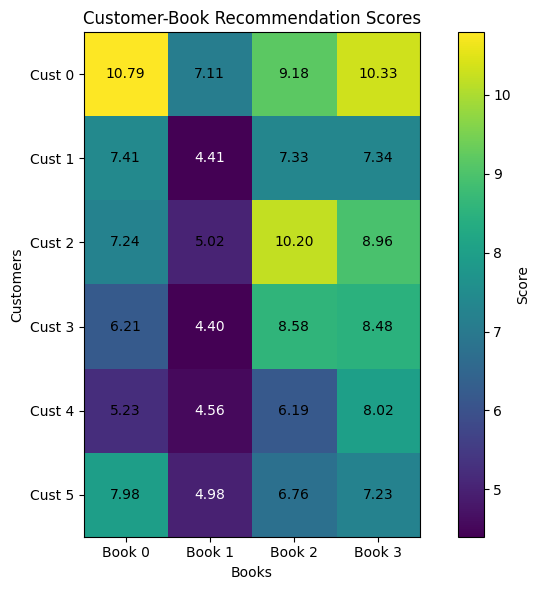

In [5]:
plt.figure(figsize=(8, 6))
plt.imshow(customer_book_scores, cmap='viridis', interpolation='nearest')
plt.colorbar(label='Score')

# Setting labels
plt.title('Customer-Book Recommendation Scores')
plt.xlabel('Books')
plt.ylabel('Customers')
plt.xticks(ticks=range(4), labels=[f'Book {i}' for i in range(4)])
plt.yticks(ticks=range(6), labels=[f'Cust {i}' for i in range(6)])

# Annotate the matrix values
for i in range(6):
    for j in range(4):
        plt.text(j, i, f"{customer_book_scores[i, j]:.2f}",
                 ha="center", va="center", color="w" if customer_book_scores[i, j] < 5 else "black")

plt.tight_layout()
plt.show()